# Food-101 Image Classification: Frozen Pretrained Backbones
Part 1 of 2. Compares GoogLeNet, MobileNetV3-Small and ResNet18 as frozen feature extractors with a custom MLP head.



---
#**PART- A**
- In this notebook, we will analyse the architectural difference between 3 CNN
models and perform transfer learning on them to accurately predict 101 different classes from the Food101 Dataset.
- We will use the weights obtained from the ImageNet Dataset and perform transfer learning on the following 3 pre-trained models and compare their results:
1. GoogLeNet
2. MobileNet V3
3. ResNet
- We will replace the classification head or fully connected layers, freeze pretrained layers, and compare performance on the Food101 dataset.



---

#**IMPORT LIBRARIES**

We will import all the necessary libraries. PyTorch and Torchvision libraries helps in building and training deep learning models. Torchvision helps in providing access to pretrained CNN architectures and the Food101 dataset.

In [ ]:
# We will import necessary libraries
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

import tarfile, os
from collections import Counter



---
#**CONFIGURATION OF DEVICE**



If a GPU is available, we use it to speed up training. Otherwise the computation is done on the CPU.

In [ ]:
# Use GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(" Device:", device)

 Device: cuda




---


#**DOWNLOADING AND EXTRACTING THE DATASET**

- In Colab, the dataset is downloaded via wget and extracted.
- This approach allows for an efficient and automatic download of large datasets directly into the development environment.
- After this, we deleted the compressed file to save storage.

In [ ]:
!wget http://data.vision.ee.ethz.ch/cvl/food-101.tar.gz

--2026-04-22 11:53:34--  http://data.vision.ee.ethz.ch/cvl/food-101.tar.gz
Resolving data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)... 129.132.52.178, 2001:67c:10ec:36c2::178
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://data.vision.ee.ethz.ch/cvl/food-101.tar.gz [following]
--2026-04-22 11:53:35--  https://data.vision.ee.ethz.ch/cvl/food-101.tar.gz
Connecting to data.vision.ee.ethz.ch (data.vision.ee.ethz.ch)|129.132.52.178|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4996278331 (4.7G) [application/x-gzip]
Saving to: ‘food-101.tar.gz’

food-101.tar.gz     100%[===================>]   4.65G  22.1MB/s    in 3m 43s  

2026-04-22 11:57:18 (21.4 MB/s) - ‘food-101.tar.gz’ saved [4996278331/4996278331]



In [ ]:
with tarfile.open("food-101.tar.gz", "r:gz") as tar:
    tar.extractall("./data")

# We remove the compressed file to save storage
os.remove("food-101.tar.gz")

/tmp/ipykernel_3295/3468607795.py:2: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall("./data")




---

#**DATA PREPROCESSING**

- The images are resized to 224 * 224 to fit the input size of pre-trained models.

- Data augmentation (horizontal flipping) is used to improve model generalisation.

- We do normalization using ImageNet statistics as pretrained models were trained on ImageNet.

In [ ]:
# We now define image size and batch size
IMAGE_SIZE = 224
BATCH_SIZE = 32

# Training transformations (data augmentation)
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),  # helps generalisation
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Testing transformations (no augmentation)
test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])



---

#**LOADING DATASET**

We will now load the data.
The Food101 dataset contains 101 food categories, with 101,000 images. For each class, manually reviewed are provided as follows:
- Training set: 750 images per class
- Test set: 250 images

DataLoaders are used for efficient loading of data in batches during training.

In [ ]:
# Load Food101 dataset
train_full = datasets.Food101(root="./data", split="train",
                             transform=train_transform, download=False)

test_dataset = datasets.Food101(root="./data", split="test",
                               transform=test_transform, download=False)

class_names = train_full.classes
print("Total classes:", len(class_names))

Total classes: 101




---


#**DATA SPLITTING FOR TRAINING AND VALIDATION SET**

In [ ]:
train_size = int(0.8 * len(train_full))
val_size = len(train_full) - train_size

train_dataset, val_dataset = random_split(train_full, [train_size, val_size])



---
#**DATALOADERS**


In [ ]:
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=2, pin_memory=True)

val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=2, pin_memory=True)

test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE,
                         shuffle=False, num_workers=2, pin_memory=True)

#**VISUALISING SAMPLE IMAGES**

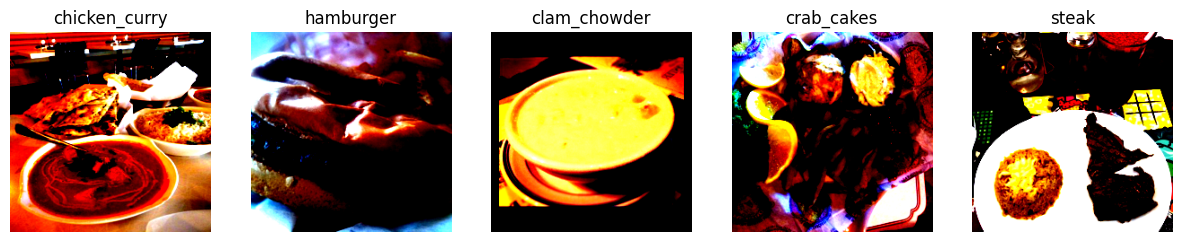

In [ ]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(1, 5, figsize=(15,5))

for i in range(5):
    img = images[i].permute(1,2,0).numpy()
    axes[i].imshow(img)
    axes[i].set_title(class_names[labels[i]])
    axes[i].axis("off")

plt.show()



---

#**TRAINING FUNCTION**

- The below function performs forward propagation, calculates the loss and updates the model weights using backpropagation.
- The pretrained layers are frozen, so only the classification head is trained.

In [ ]:
def train(model, train_loader, val_loader, optimizer, criterion, epochs=5):
    train_losses = []
    val_acc_list = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backpropagation
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        train_loss = running_loss / len(train_loader)
        val_acc = evaluate(model, val_loader)

        train_losses.append(train_loss)
        val_acc_list.append(val_acc)

        print(f"Epoch {epoch+1}: Loss={train_loss:.4f}, Val Acc={val_acc:.2f}%")

    return train_losses, val_acc_list



---

#**EVALUATION FUNCTION**

- The model is examined on the test dataset.
- The accuracy is the percentage of images that are classified correctly.

In [ ]:
def evaluate(model, loader):
    model.eval()
    correct, total = 0, 0

    with torch.no_grad(): # disable gradients for faster evaluation
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            _, preds = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (preds == labels).sum().item()

    return 100 * correct / total

#**MODEL 1: GOOGLENET**

- GoogLeNet employs Inception modules to efficiently extract multi-scale features.
- It trades off between computational efficiency and accuracy.

In [ ]:
# Load pretrained GoogLeNet
googlenet = models.googlenet(weights=models.GoogLeNet_Weights.DEFAULT)

# Freeze all the pretrained layers
for p in googlenet.parameters():
    p.requires_grad = False

# Disable auxiliary outputs
googlenet.aux_logits = False
googlenet.aux1 = None
googlenet.aux2 = None

# Replace classifier (model head)
googlenet.fc = nn.Sequential(
    nn.Linear(1024, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 101)
)

# Move model to device
googlenet = googlenet.to(device)

# Define loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(googlenet.fc.parameters(), lr=0.001)

# Train and Evaluate
google_loss, google_acc = train(googlenet, train_loader, val_loader, optimizer, criterion)
google_test = evaluate(googlenet, test_loader)

Epoch 1: Loss=3.4566, Val Acc=32.51%
Epoch 2: Loss=2.9437, Val Acc=36.15%
Epoch 3: Loss=2.8345, Val Acc=38.06%
Epoch 4: Loss=2.7843, Val Acc=39.69%
Epoch 5: Loss=2.7429, Val Acc=40.13%




---
#**MODEL 2: MOBILENET V3**


- MobileNetV3 is a lightweight architecture that is optimized for speed and efficiency.
- It uses depthwise separable convolutions which is faster but sometimes a little less accurate.

In [ ]:
# Load pretrained MobileNetV3
mobilenet = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)

# Freeze layers
for p in mobilenet.parameters():
    p.requires_grad = False

# Replace classifier
mobilenet.classifier = nn.Sequential(
    nn.Linear(576, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 101)
)

mobilenet = mobilenet.to(device)

# Loss and optimizer
optimizer = optim.Adam(mobilenet.classifier.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

# Train and Evaluate
mobile_loss, mobile_acc = train(mobilenet, train_loader, val_loader, optimizer, criterion)
mobile_test = evaluate(mobilenet, test_loader)

Epoch 1: Loss=3.1387, Val Acc=36.90%
Epoch 2: Loss=2.5892, Val Acc=41.15%
Epoch 3: Loss=2.4325, Val Acc=44.07%
Epoch 4: Loss=2.3347, Val Acc=45.62%
Epoch 5: Loss=2.2710, Val Acc=45.62%




---
#**MODEL 3: RESNET18**


- ResNet uses residual connections to train deeper networks.
- For Food101 classification we freeze pretrained layers and replace the classification head by 3 fully connected layers.

In [ ]:
# Load pretrained ResNet18
resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze all layers
for p in resnet.parameters():
    p.requires_grad = False

# Replace final layer with custom head
resnet.fc = nn.Sequential(
    nn.Linear(resnet.fc.in_features, 512),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Linear(256, 101)
)

resnet = resnet.to(device)

# Loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet.fc.parameters(), lr=0.001)

# Train and Evaluate
resnet_loss, resnet_acc = train(resnet, train_loader, val_loader, optimizer, criterion)
resnet_test = evaluate(resnet, test_loader)

Epoch 1: Loss=3.1183, Val Acc=37.85%
Epoch 2: Loss=2.5843, Val Acc=41.87%
Epoch 3: Loss=2.4570, Val Acc=44.45%
Epoch 4: Loss=2.3942, Val Acc=45.02%
Epoch 5: Loss=2.3379, Val Acc=45.97%




---

#**MODEL COMPARISON**

We will now compare accuracy of all 3 models. We will see which model performed better and gave highr accuracy. We'll visualise how well it predicted the objects. The model which performs best will then be chosen for Part-b.

In [ ]:
print("GoogLeNet Test Accuracy:", google_test)

GoogLeNet Test Accuracy: 44.05940594059406


In [ ]:
print("MobileNet Test Accuracy:", mobile_test)

MobileNet Test Accuracy: 49.86534653465347


In [ ]:
print("ResNet Test Accuracy:", resnet_test)

ResNet Test Accuracy: 49.904950495049505


In [ ]:
print("\nFinal Results:")
print("ResNet Test Accuracy:", resnet_test)
print("GoogLeNet Test Accuracy:", google_test)
print("MobileNet Test Accuracy:", mobile_test)


Final Results:
ResNet Test Accuracy: 49.904950495049505
GoogLeNet Test Accuracy: 44.05940594059406
MobileNet Test Accuracy: 49.86534653465347


#**VISUALISING THE ACCURACY AND LOSSES**

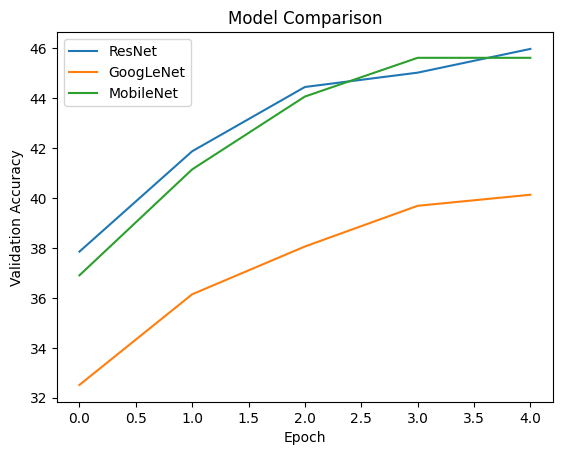

In [ ]:
# Accuracy
plt.plot(resnet_acc, label="ResNet")
plt.plot(google_acc, label="GoogLeNet")
plt.plot(mobile_acc, label="MobileNet")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.title("Model Comparison")
plt.show()

- GoogLeNet showed a steady, but limited, learning as the validation accuracy increased from Epoch 1 (32.51%) to Epoch 5 (40.13%).
- MobileNetV3 got better results, from 36.90% to 45.62% showing a stronger learning ability than GoogLeNet. However, its improvement saturated in the last epochs.
- The best performing model was ResNet18 with a validation accuracy of 37.85% in Epoch 1 and 45.97% in Epoch 5. It outperformed GoogLeNet consistently and outperformed MobileNetV3 slightly.
- ResNet18 is more robust which shows a consistent learning trend and better feature representation than MobileNetV3 that has a similar final test accuracy (about 49.8%), and GoogLeNet performs poorly.


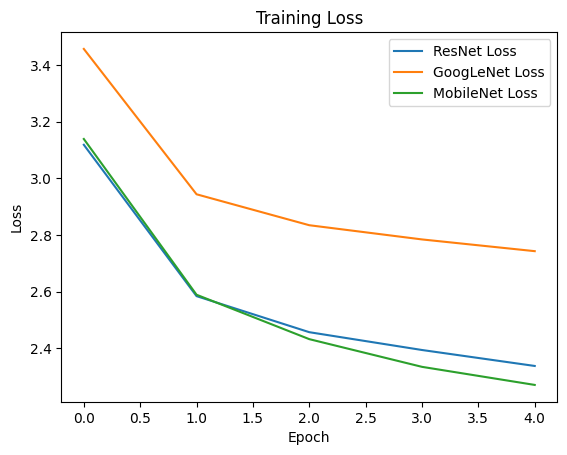

In [ ]:
# Loss
plt.plot(resnet_loss, label="ResNet Loss")
plt.plot(google_loss, label="GoogLeNet Loss")
plt.plot(mobile_loss, label="MobileNet Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training Loss")
plt.show()

- The loss of GoogLeNet is reduced from 3.4566 to 2.7429, showing it is learning, but at a slower rate.
- The MobileNetV3 shows a steeper drop from 3.1387 to 2.2710, which implies that it is better optimized than GoogLeNet.
- The ResNet18 shows a stable decrease from 3.1183 to 2.3379, which is the sign of effective learning.
-	MobileNetV3 does a little less loss than ResNet18, but the accuracy does not increase proportionally. This means lower loss does not always mean better generalization, while ResNet18 has a better trade-off between loss and accuracy.


# **CONFUSION MATRIX**

- The classification performance of all three models is analyzed using confusion matrices.
- There are many classes (101), so only a subset of the matrix is shown.


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def get_preds(model, loader):
    model.eval()
    preds, labels_list = [], []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            _, pred = torch.max(outputs, 1)

            preds.extend(pred.cpu().numpy())
            labels_list.extend(labels.numpy())

    return labels_list, preds

**FOR GOOGLENET**

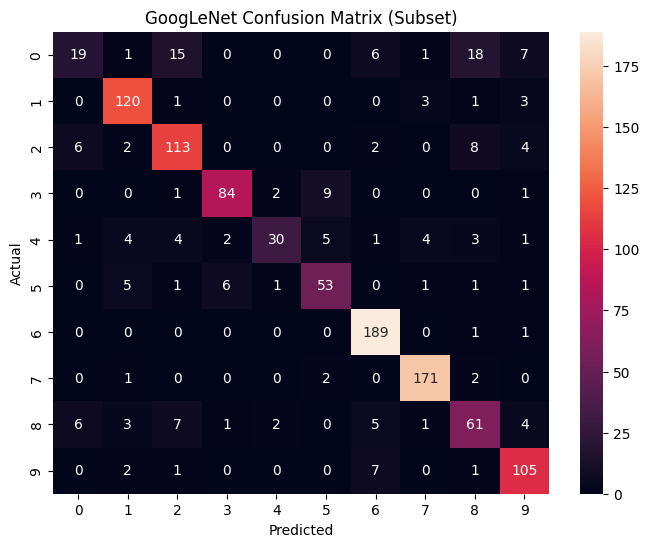

In [ ]:
true_g, pred_g = get_preds(googlenet, test_loader)
cm_google = confusion_matrix(true_g, pred_g)

plt.figure(figsize=(8,6))
sns.heatmap(cm_google[:10, :10], annot=True, fmt='d')
plt.title("GoogLeNet Confusion Matrix (Subset)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**FOR MOBILENET**

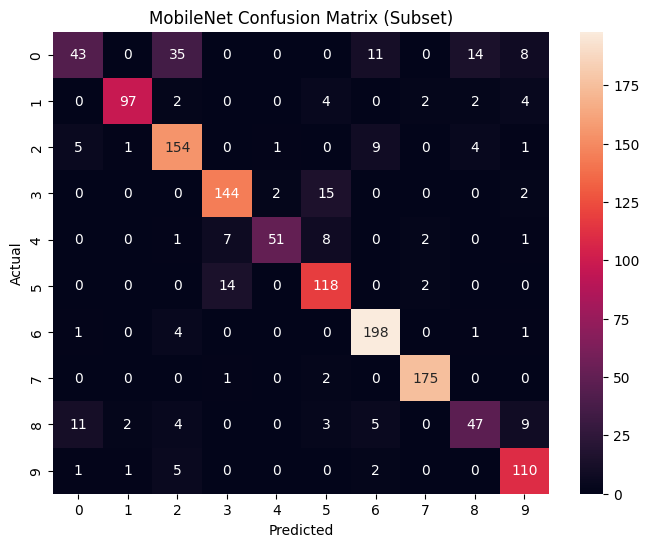

In [ ]:
true_m, pred_m = get_preds(mobilenet, test_loader)
cm_mobile = confusion_matrix(true_m, pred_m)

plt.figure(figsize=(8,6))
sns.heatmap(cm_mobile[:10, :10], annot=True, fmt='d')
plt.title("MobileNet Confusion Matrix (Subset)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**FOR RESNET**

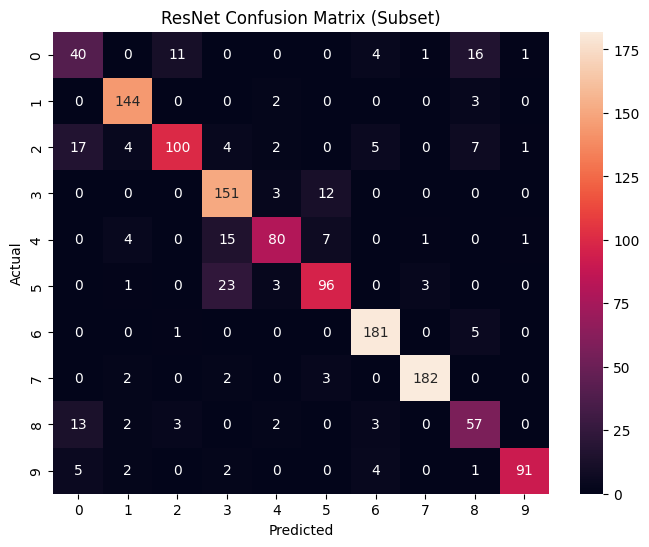

In [ ]:
true_r, pred_r = get_preds(resnet, test_loader)
cm_resnet = confusion_matrix(true_r, pred_r)

plt.figure(figsize=(8,6))
sns.heatmap(cm_resnet[:10, :10], annot=True, fmt='d')
plt.title("ResNet Confusion Matrix (Subset)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

- The confusion matrices show the differences in classification ability among all three models.
-	ResNet18 shows the most robust diagonal pattern, representing more correct predictions.
-	MobileNetV3 also shows a reasonable diagonal dominance, but with a few more misclassifications.
-	We observe the lower accuracy (44.06%) confirming the lesser diagonal concentration for GoogleNet.
